# 01 · SQL layer, EDA and hypothesis testing

**Goal:** understand who churns, using SQL for the aggregations, then test 5
business hypotheses with proper statistics. Every hypothesis ends with a
one-sentence conclusion for the business.

Data: Kaggle *Credit Card Customers* (`BankChurners.csv`), 10,127 customers,
one row per customer, a single snapshot (no time series).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import load_config, set_seed
from src.data import build_duckdb, load_dataset, run_sql_file
from src.plots import ACCENT, MUTED, NEUTRAL, RISK, save, save_table, setup_style
from src import stats_tests as st

cfg = load_config()
SEED = set_seed()
setup_style()
pd.set_option("display.width", 160, "display.max_columns", 30)

db = build_duckdb()
print("DuckDB file:", Path(db).relative_to(Path.cwd().parent))

DuckDB file: data/churn.duckdb


## 1. SQL layer
All queries live in `sql/` and are executed against DuckDB through
`src.data.run_sql_file`. They are written in PostgreSQL-compatible SQL.

### Q1 — portfolio overview (`sql/01_churn_overview.sql`)

In [2]:
overview = run_sql_file("01_churn_overview")
save_table(overview, "sql_q1_overview")
overview

,churned,customers,share,avg_trans_ct,avg_trans_amt,avg_revolving_bal,avg_products,avg_inactive_months
0,0,8500,0.8393,68.7,4655.0,1257.0,3.91,2.27
1,1,1627,0.1607,44.9,3095.0,673.0,3.28,2.69


In [3]:
churn_rate = overview.loc[overview.churned == 1, "share"].item()
print(f"Overall churn rate: {churn_rate:.1%}  ->  a model predicting 'nobody churns' "
      f"already has {1 - churn_rate:.1%} accuracy (that's why accuracy is useless here).")

Overall churn rate: 16.1%  ->  a model predicting 'nobody churns' already has 83.9% accuracy (that's why accuracy is useless here).


Churners make **far fewer and smaller transactions**, carry a lower revolving
balance and hold fewer products. Demographics are checked next.

### Q2 — churn by segment (`GROUPING SETS`)

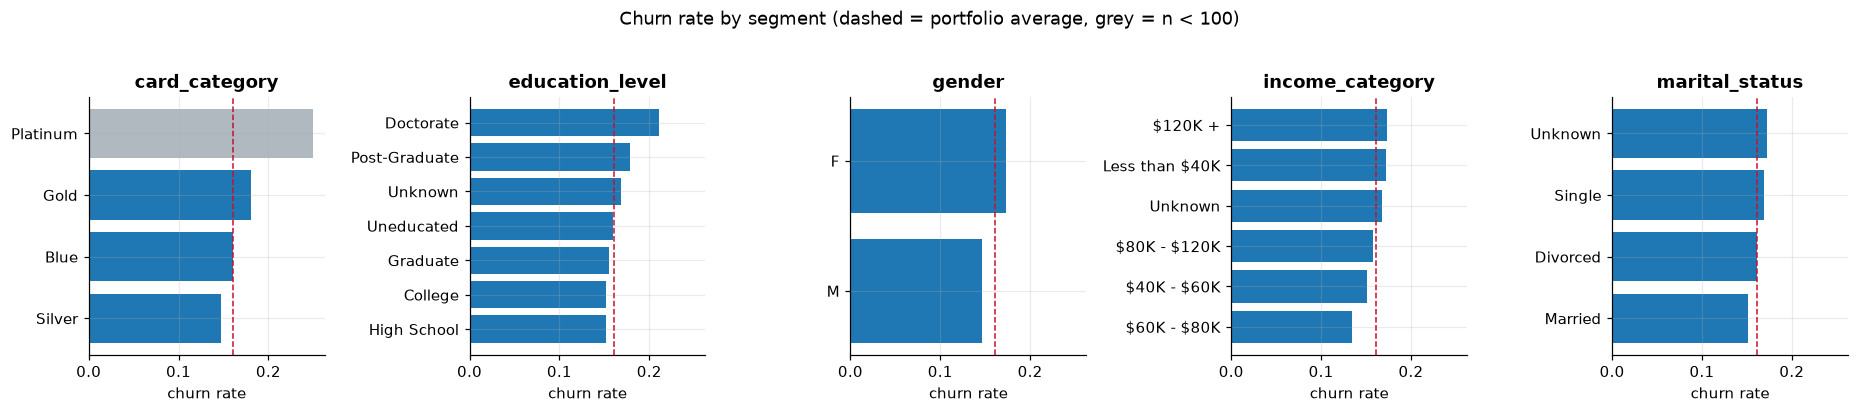

,dimension,segment,customers,churners,churn_rate,small_sample
0,card_category,Platinum,20,5.0,0.2500,True
4,education_level,Doctorate,451,95.0,0.2106,False
1,card_category,Gold,116,21.0,0.1810,False
5,education_level,Post-Graduate,516,92.0,0.1783,False
11,gender,F,5358,930.0,0.1736,False
13,income_category,$120K +,727,126.0,0.1733,False
19,marital_status,Unknown,749,129.0,0.1722,False
14,income_category,Less than $40K,3561,612.0,0.1719,False


In [4]:
seg = run_sql_file("02_churn_by_segment")
save_table(seg, "sql_q2_segments")

dims = seg["dimension"].unique()
fig, axes = plt.subplots(1, len(dims), figsize=(17, 3.6), sharex=True)
for ax, d in zip(axes, dims):
    s = seg[seg.dimension == d].sort_values("churn_rate")
    colors = [MUTED if small else ACCENT for small in s.small_sample]
    # escape '$' so matplotlib does not switch to math mode on income labels
    ax.barh(s["segment"].str.replace("$", r"\$", regex=False), s["churn_rate"], color=colors)
    ax.axvline(churn_rate, color=RISK, ls="--", lw=1)
    ax.set_title(d)
    ax.set_xlabel("churn rate")
fig.suptitle("Churn rate by segment (dashed = portfolio average, grey = n < 100)", y=1.03)
fig.tight_layout()
save(fig, "eda_churn_by_segment")
plt.show()
seg.sort_values("churn_rate", ascending=False).head(8)

Demographic differences are **modest** (most segments within ±3 p.p. of the
16% average; the extremes are Doctorate at 21% and Platinum with n = 20, too
few to trust). Demographics will not drive the campaign — behaviour will.

### Q3 — rule-based activity segmentation (`CASE` + window share)

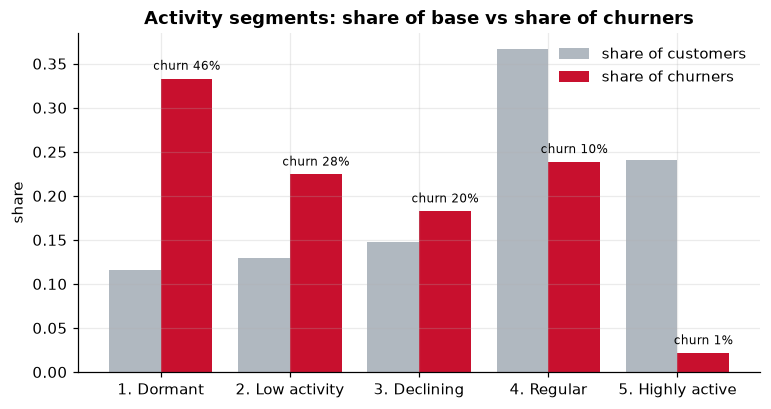

,activity_segment,customers,share_of_base,churn_rate,churners,share_of_all_churners,avg_trans_amt
0,1. Dormant,1177,0.1162,0.4605,542.0,0.3331,1736.0
1,2. Low activity,1305,0.1289,0.2797,365.0,0.2243,1653.0
2,3. Declining,1495,0.1476,0.1987,297.0,0.1825,4122.0
3,4. Regular,3710,0.3663,0.1046,388.0,0.2385,3974.0
4,5. Highly active,2440,0.2409,0.0143,35.0,0.0215,7989.0


In [5]:
act = run_sql_file("03_activity_segmentation")
save_table(act, "sql_q3_activity_segments")

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(act))
ax.bar(x - 0.2, act["share_of_base"], 0.4, color=MUTED, label="share of customers")
ax.bar(x + 0.2, act["share_of_all_churners"], 0.4, color=RISK, label="share of churners")
ax.set_xticks(x, act["activity_segment"])
ax.set_ylabel("share")
ax.set_title("Activity segments: share of base vs share of churners")
for i, r in act.iterrows():
    ax.text(i + 0.2, r.share_of_all_churners + 0.01, f"churn {r.churn_rate:.0%}",
            ha="center", fontsize=8)
ax.legend()
save(fig, "eda_activity_segments")
plt.show()
act

### Q4 — spend deciles (`NTILE(10)`)

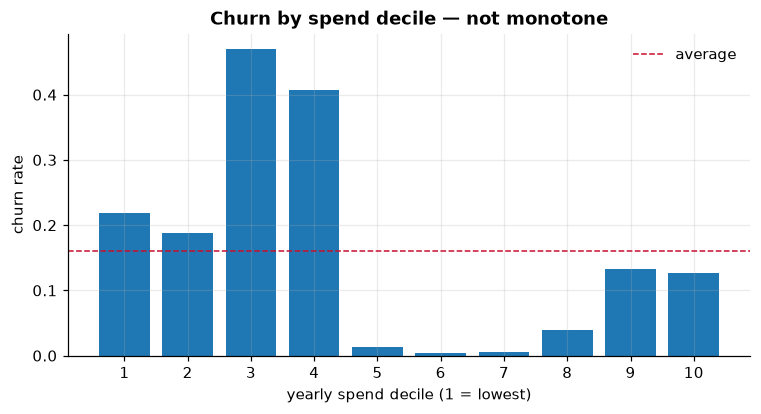

,spend_decile,min_spend,max_spend,customers,churn_rate,spend_lost_to_churn
0,1,510,1501,1013,0.2192,214966.0
1,2,1501,1914,1013,0.1885,334017.0
2,3,1914,2411,1013,0.4699,1038908.0
3,4,2412,3193,1013,0.4077,1086425.0
4,5,3193,3900,1013,0.0128,43884.0
5,6,3901,4267,1013,0.0039,15831.0
6,7,4268,4573,1013,0.0049,22478.0
7,8,4573,4926,1012,0.0395,191644.0
8,9,4927,8213,1012,0.1334,935343.0
9,10,8215,18484,1012,0.1265,1152111.0


In [6]:
dec = run_sql_file("04_spend_deciles_ntile")
save_table(dec, "sql_q4_spend_deciles")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(dec["spend_decile"], dec["churn_rate"], color=ACCENT)
ax.axhline(churn_rate, color=RISK, ls="--", lw=1, label="average")
ax.set_xticks(dec["spend_decile"])
ax.set_xlabel("yearly spend decile (1 = lowest)")
ax.set_ylabel("churn rate")
ax.set_title("Churn by spend decile — not monotone")
ax.legend()
save(fig, "eda_spend_deciles")
plt.show()
dec

Strongly **non-monotone**: churn peaks in deciles 3–4 (~40–47%), is almost
zero in deciles 5–7, and rises again in 9–10 (~13%). Deciles 3–4 and 9–10
also hold most of the spend lost to churn. A linear model cannot represent
this shape with one coefficient — a first hint that a tree model will win.
(The two high-churn bands probably reflect different customer types, e.g.
low-engagement vs high-spend customers switching to a competitor.)

### Q5 — riskiest income × card micro-segments (`RANK`, `DENSE_RANK`)

In [7]:
ranked = run_sql_file("05_rank_segments")
save_table(ranked, "sql_q5_ranked_segments")
ranked.head(10)

,card_category,income_category,customers,churn_rate,global_risk_rank,rank_within_card
0,Silver,$80K - $120K,117,0.1880,1,1
1,Silver,$120K +,60,0.1833,2,2
2,Blue,$120K +,645,0.1752,3,1
3,Blue,Less than $40K,3403,0.1722,4,2
4,Blue,Unknown,1045,0.1684,5,3
5,Blue,$80K - $120K,1395,0.1541,6,4
6,Silver,Less than $40K,130,0.1538,7,3
7,Blue,$40K - $60K,1675,0.1534,8,5
8,Blue,$60K - $80K,1273,0.1351,9,6
9,Silver,Unknown,53,0.1321,10,4


### Q6 — the inactivity "cliff" (`LAG`)
The dataset has no monthly history, so `LAG` runs over ordered inactivity
levels rather than calendar time.

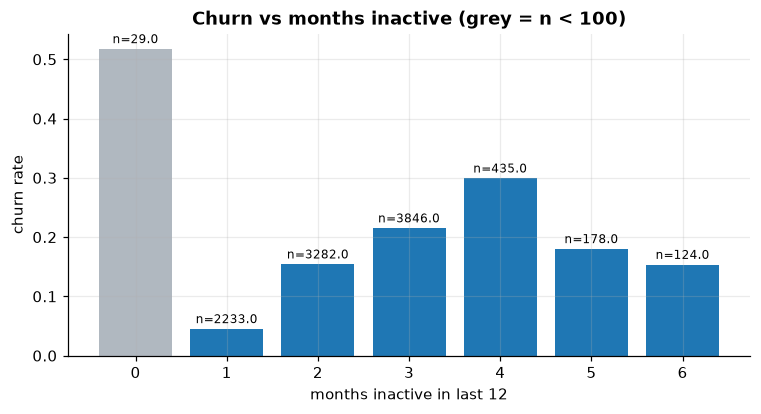

,inactive_months,customers,churn_rate,prev_churn_rate,delta_vs_prev,cumulative_customers
0,0,29,0.5172,NaN,NaN,29.0
1,1,2233,0.0448,0.5172,-0.4724,2262.0
2,2,3282,0.1539,0.0448,0.1091,5544.0
3,3,3846,0.2148,0.1539,0.0609,9390.0
4,4,435,0.2989,0.2148,0.0841,9825.0
5,5,178,0.1798,0.2989,-0.1191,10003.0
6,6,124,0.1532,0.1798,-0.0266,10127.0


In [8]:
lag = run_sql_file("06_inactivity_lag")
save_table(lag, "sql_q6_inactivity_lag")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(lag["inactive_months"], lag["churn_rate"],
       color=[MUTED if n < 100 else ACCENT for n in lag["customers"]])
for _, r in lag.iterrows():
    ax.text(r.inactive_months, r.churn_rate + 0.01, f"n={r.customers}", ha="center", fontsize=8)
ax.set_xlabel("months inactive in last 12")
ax.set_ylabel("churn rate")
ax.set_title("Churn vs months inactive (grey = n < 100)")
save(fig, "eda_inactivity")
plt.show()
lag

Customers with **0** inactive months churn the most, but n = 29 — noise.
Among well-populated levels churn climbs steadily from 1 month (~4%) to
4 months (~30%); the largest single step is **1 → 2 months (+11 p.p.)**
(`delta_vs_prev`). Levels 5–6 are lower but small (n < 200). A reactivation
trigger should fire at **2 inactive months**.

### Q7 — product holding (cross-sell angle, chained CTEs)

In [9]:
prod = run_sql_file("07_product_holding_cte")
save_table(prod, "sql_q7_product_holding")
prod

,holding_band,customers,churn_rate,churn_lift_vs_avg,avg_trans_amt
0,1-2 products,2153,0.2689,1.67,7118.0
1,3-4 products,4217,0.1482,0.92,3854.0
2,5-6 products,3757,0.1126,0.70,3466.0


Customers with 1–2 products churn ~1.7× the average — and they are the
**highest spenders** on the card. They use the card a lot but have no other
ties to the bank, which makes them both valuable and easy to lose: the
strongest cross-sell case.

### Q8 — transparent rule-based risk score (the "no-ML" benchmark)

In [10]:
flags = run_sql_file("08_risk_flags_cte")
save_table(flags, "sql_q8_risk_flags")
flags

,risk_flags,customers,share_of_base,churn_rate,cum_recall_if_targeted,cum_share_targeted
0,5,74,0.0073,0.9865,0.0449,0.0073
1,4,370,0.0365,0.8973,0.2489,0.0438
2,3,1133,0.1119,0.4766,0.5808,0.1557
3,2,2695,0.2661,0.1610,0.8476,0.4218
4,1,3857,0.3809,0.0547,0.9773,0.8027
5,0,1998,0.1973,0.0185,1.0000,1.0000


A 5-rule score is already informative: churn rises steeply with the number
of flags. This is the **benchmark the ML model must beat** — if it cannot,
the bank should just use these rules. (Compared in notebook 02.)

## 2. Distributions of key behavioural features

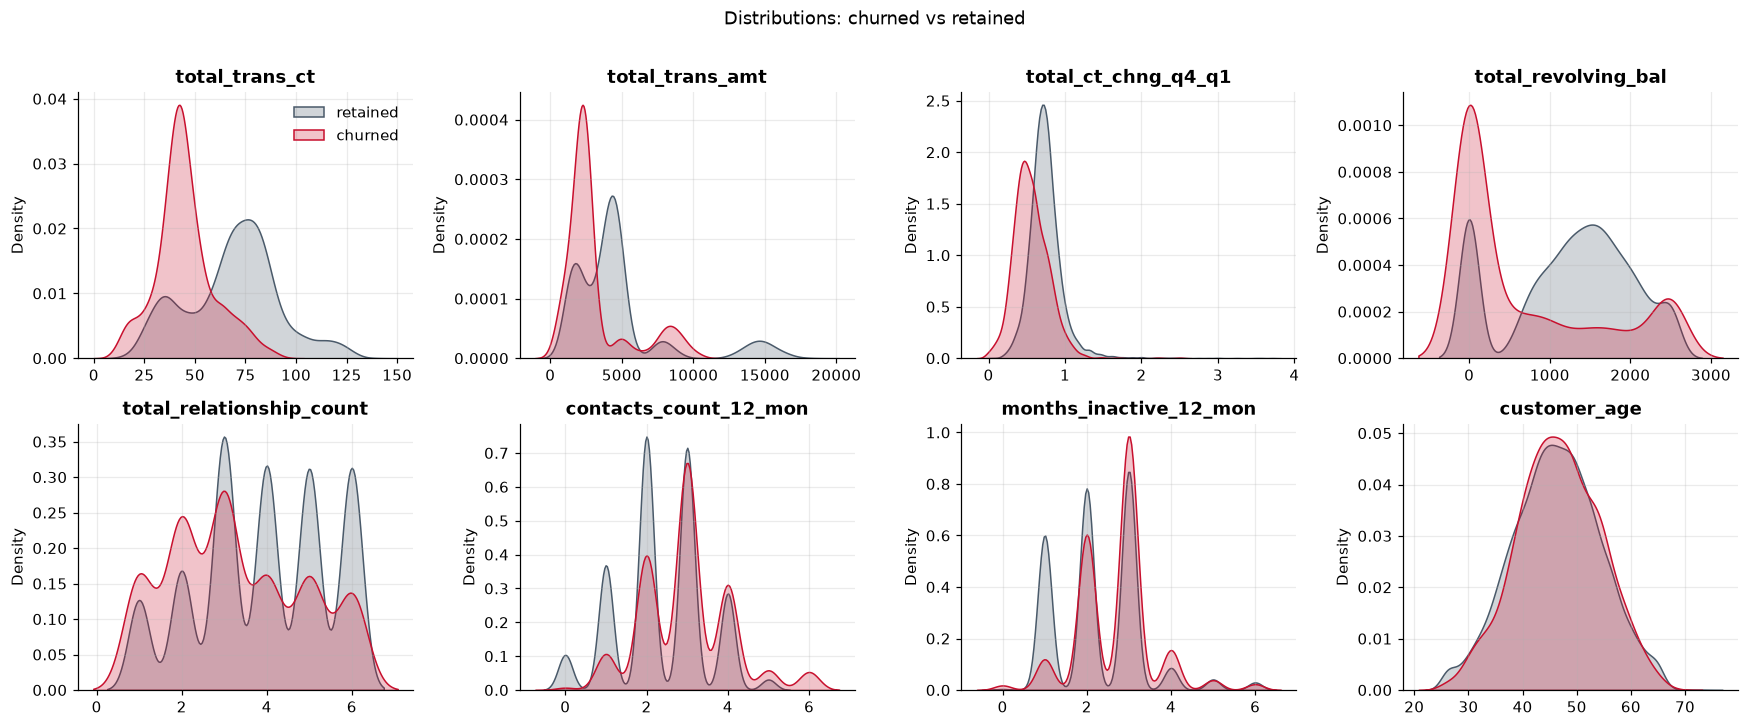

In [11]:
df = load_dataset()
key = ["total_trans_ct", "total_trans_amt", "total_ct_chng_q4_q1", "total_revolving_bal",
       "total_relationship_count", "contacts_count_12_mon", "months_inactive_12_mon", "customer_age"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), key):
    for label, color in [(0, NEUTRAL), (1, RISK)]:
        sns.kdeplot(df.loc[df.churned == label, col], ax=ax, color=color, fill=True,
                    alpha=0.25, common_norm=False, label="churned" if label else "retained",
                    warn_singular=False)
    ax.set_title(col)
    ax.set_xlabel("")
axes[0, 0].legend()
fig.suptitle("Distributions: churned vs retained", y=1.01)
fig.tight_layout()
save(fig, "eda_distributions")
plt.show()

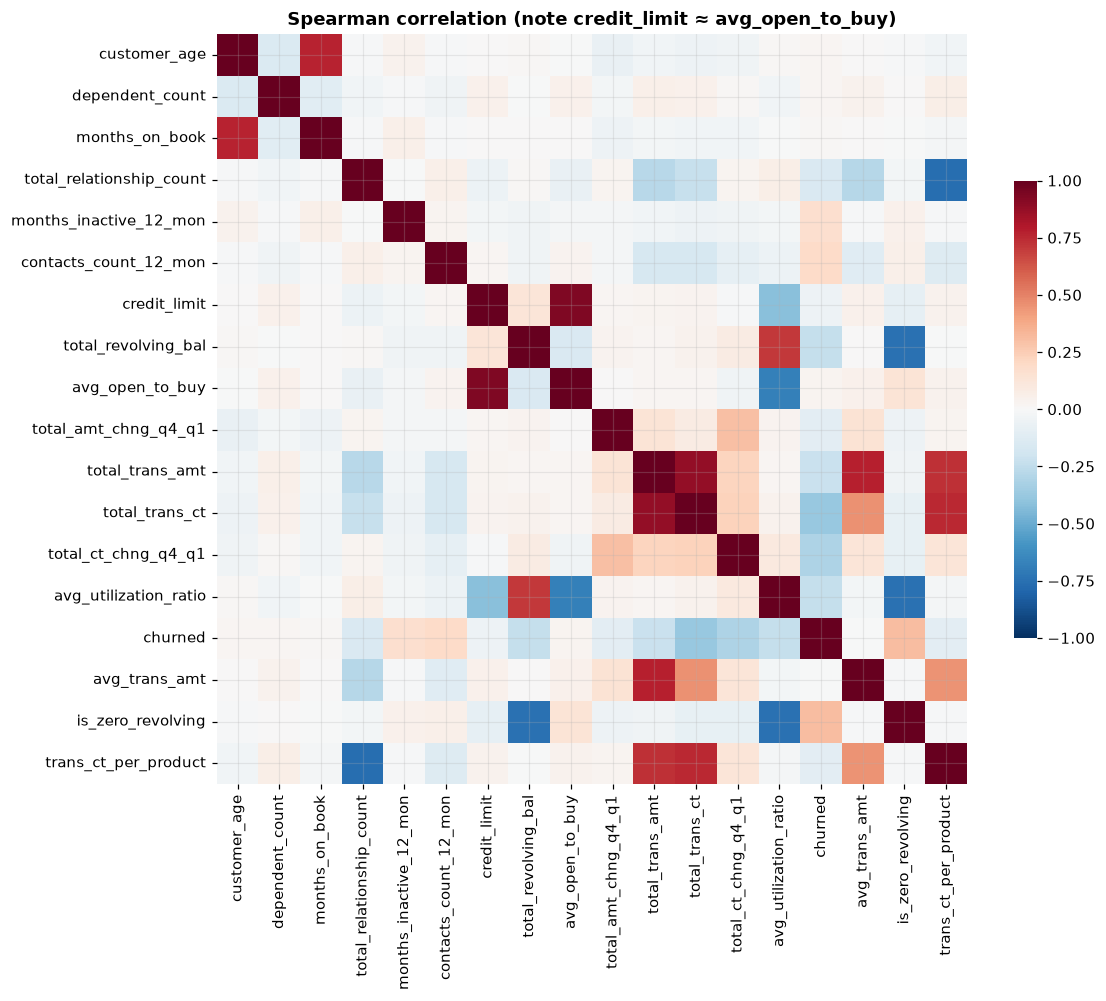

total_trans_ct           -0.376
total_ct_chng_q4_q1      -0.312
is_zero_revolving         0.311
total_revolving_bal      -0.241
avg_utilization_ratio    -0.240
total_trans_amt          -0.224
contacts_count_12_mon     0.189
months_inactive_12_mon    0.172
Name: churned, dtype: float64


In [12]:
num = df.select_dtypes("number").drop(columns=["clientnum"])
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True,
            cbar_kws={"shrink": 0.6})
ax.set_title("Spearman correlation (note credit_limit ≈ avg_open_to_buy)")
save(fig, "eda_correlation")
plt.show()
print(corr["churned"].drop("churned").sort_values(key=abs, ascending=False).round(3).head(8))

`credit_limit` and `avg_open_to_buy` are almost perfectly correlated
(open-to-buy = limit − revolving balance). That is harmless for trees but
makes logistic-regression coefficients unstable, so the baseline drops one.

## 3. Hypothesis testing

**Test selection logic**

| Variable type | Test | Effect size |
|---|---|---|
| binary/categorical vs churn | χ² test of independence | Cramér's V (+ risk ratio) |
| skewed / ordinal numeric | Mann-Whitney U | rank-biserial r |
| ~symmetric numeric, mean matters | Welch t-test | Cohen's d |

Five hypotheses are tested together, so p-values get a **Holm–Bonferroni**
correction (family-wise error rate ≤ 5%). With n ≈ 10k, tiny effects become
"significant", so a finding is called **actionable** only if it is
significant after correction *and* the effect size is at least *small*.

In [13]:
df["few_products"] = (df.total_relationship_count <= 2).astype(int)
df["inactive_3plus"] = (df.months_inactive_12_mon >= 3).astype(int)

results = [
    st.mann_whitney(df, "total_ct_chng_q4_q1", "churned",
                    "H1: churners show a larger drop in transaction count (Q4 vs Q1)"),
    st.chi_square(df, "few_products", "churned",
                  "H2: customers with 1-2 products churn more than those with 3+"),
    st.chi_square(df, "is_zero_revolving", "churned",
                  "H3: customers with zero revolving balance churn more"),
    st.chi_square(df, "inactive_3plus", "churned",
                  "H4: customers inactive 3+ months churn more"),
    st.welch_t_test(df, "customer_age", "churned",
                    "H5: churners differ in age from retained customers"),
]
hyp = st.correct_pvalues(results, alpha=0.05, method="holm")
hyp[["hypothesis", "test", "p_value", "p_adjusted", "effect_size_name", "effect_size",
     "effect_magnitude", "reject_h0", "actionable"]]

,hypothesis,test,p_value,p_adjusted,effect_size_name,effect_size,effect_magnitude,reject_h0,actionable
0,H1: churners show a larger drop in transaction...,Mann-Whitney U (two-sided),1.908241e-216,9.541203e-216,rank-biserial r (churned vs retained),-0.490623,medium,True,True
1,H2: customers with 1-2 products churn more tha...,Chi-square independence,2.098224e-53,6.294673e-53,Cramér's V,0.152872,small,True,True
2,H3: customers with zero revolving balance chur...,Chi-square independence,3.634122e-214,1.453649e-213,Cramér's V,0.310380,medium,True,True
3,H4: customers inactive 3+ months churn more,Chi-square independence,7.508464e-49,1.501693e-48,Cramér's V,0.145973,small,True,True
4,H5: churners differ in age from retained custo...,Welch t-test,5.771863e-02,5.771863e-02,Cohen's d,0.050453,negligible,False,False


In [14]:
# Risk ratios: the most business-friendly way to state a binary finding.
rr = {}
for flag in ["few_products", "is_zero_revolving", "inactive_3plus"]:
    rr[flag] = st.risk_ratio(df, flag, "churned")
    w, wo, ratio = rr[flag]
    print(f"{flag:18s}: churn {w:.1%} with flag vs {wo:.1%} without  ->  x{ratio:.2f}")

declined = (df.total_ct_chng_q4_q1 < 0.6).astype(int)
df["tx_drop_40pct"] = declined
w, wo, ratio = st.risk_ratio(df, "tx_drop_40pct", "churned")
print(f"{'tx count -40%+':18s}: churn {w:.1%} with flag vs {wo:.1%} without  ->  x{ratio:.2f}")
for r in results:
    print("\n", r.hypothesis, "\n   ", r.detail)

few_products      : churn 26.9% with flag vs 13.1% without  ->  x2.05
is_zero_revolving : churn 36.2% with flag vs 9.6% without  ->  x3.77
inactive_3plus    : churn 22.0% with flag vs 11.2% without  ->  x1.96
tx count -40%+    : churn 35.8% with flag vs 8.5% without  ->  x4.22

 H1: churners show a larger drop in transaction count (Q4 vs Q1) 
    median churned=0.531, median retained=0.721

 H2: customers with 1-2 products churn more than those with 3+ 
    churn rate by group: {0: 0.131, 1: 0.269}; min expected count=346

 H3: customers with zero revolving balance churn more 
    churn rate by group: {0: 0.096, 1: 0.362}; min expected count=397

 H4: customers inactive 3+ months churn more 
    churn rate by group: {0: 0.112, 1: 0.22}; min expected count=736

 H5: churners differ in age from retained customers 
    mean churned=46.66, mean retained=46.26


### Conclusions for the business (one sentence each)
The sentences are generated from the numbers above so they never drift from
the results.

In [15]:
w1, wo1, r1 = st.risk_ratio(df, "tx_drop_40pct", "churned")
w2, wo2, r2 = rr["few_products"]
w3, wo3, r3 = rr["is_zero_revolving"]
w4, wo4, r4 = rr["inactive_3plus"]
h5 = hyp.iloc[4]
business = [
    f"H1 confirmed: customers whose transaction count fell 40%+ quarter-on-quarter churn {w1:.0%} vs {wo1:.0%} — usage decline is the earliest warning signal.",
    f"H2 confirmed: customers with only 1-2 products churn {r2:.1f}x more often ({w2:.0%} vs {wo2:.0%}) — selling a second product is a retention lever.",
    f"H3 confirmed: customers who don't carry a balance churn {r3:.1f}x more ({w3:.0%} vs {wo3:.0%}) — the card is a 'backup card' for them.",
    f"H4 confirmed but weaker: 3+ inactive months raise churn {r4:.1f}x ({w4:.0%} vs {wo4:.0%}) — trigger reactivation at month 2.",
    f"H5 {'not supported' if not h5.actionable else 'confirmed'}: age difference is {h5.effect_magnitude} and not significant after correction (Cohen's d = {h5.effect_size:.2f}) — don't target by age.",
]
hyp["business_conclusion"] = business
# Short versions for the slide deck (src/slides.py)
hyp["short_name"] = ["Usage decline", "Few products", "No revolving balance", "3+ inactive months", "Age"]
hyp["slide_stat"] = [f"{w1:.0%} vs {wo1:.0%} churn", f"{w2:.0%} vs {wo2:.0%} churn",
                     f"{w3:.0%} vs {wo3:.0%} churn", f"{w4:.0%} vs {wo4:.0%} churn",
                     f"Cohen's d = {h5.effect_size:.2f}"]
hyp["slide_text"] = ["Falling usage is the earliest warning sign",
                     "Customers with 1–2 products vs 3+; a second product makes them stickier",
                     "Card is a 'backup card' for customers who never carry a balance",
                     "Inactivity raises risk; trigger reactivation at month 2",
                     "Age barely differs between leavers and stayers; don't target by age"]
save_table(hyp, "hypotheses")
for b in business:
    print("•", b)

• H1 confirmed: customers whose transaction count fell 40%+ quarter-on-quarter churn 36% vs 8% — usage decline is the earliest warning signal.
• H2 confirmed: customers with only 1-2 products churn 2.0x more often (27% vs 13%) — selling a second product is a retention lever.
• H3 confirmed: customers who don't carry a balance churn 3.8x more (36% vs 10%) — the card is a 'backup card' for them.
• H4 confirmed but weaker: 3+ inactive months raise churn 2.0x (22% vs 11%) — trigger reactivation at month 2.
• H5 not supported: age difference is negligible and not significant after correction (Cohen's d = 0.05) — don't target by age.


### Caveat — correlation, not causation
These tests show *association*. "Few products → churn" might be reverse
causality (customers who already plan to leave don't buy more). Only a
randomised experiment (notebook 04) can show that an offer *causes* lower churn.